### Homework Submission 03 ###

In [27]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

--2026-10-12 13:05:29--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.03s   

2026-10-12 13:05:30 (8.20 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [28]:
import pandas as pd

df = pd.read_csv('course_lead_scoring_2026.csv')
new_df = df.T
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [29]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [30]:
categorical_features = ['industry', 'employment_status', 'location', 'lead_source']
numeric_features = ['annual_income', 'lead_score']
df_copy = df.copy()
df_copy[categorical_features] = df[categorical_features].fillna('NA')
df_copy[numeric_features] = df[numeric_features].fillna(0.0)
df_copy.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

### Question 1 ###

In [31]:
df["industry"].mode().item()

'technology'

In [32]:
df_copy.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Question 2 ###

In [33]:
import numpy as np

def computer_correlation(df, feature1, feature2):
    import numpy as np

    x = df[feature1].values
    y = df[feature2].values

    x_c = x - x.mean()                      # step 1: center
    y_c = y - y.mean()

    numerator = (x_c * y_c).sum()           # step 2
    denominator = np.sqrt((x_c**2).sum()) * np.sqrt((y_c**2).sum())   # step 3

    r = numerator / denominator
    return r

<Axes: >

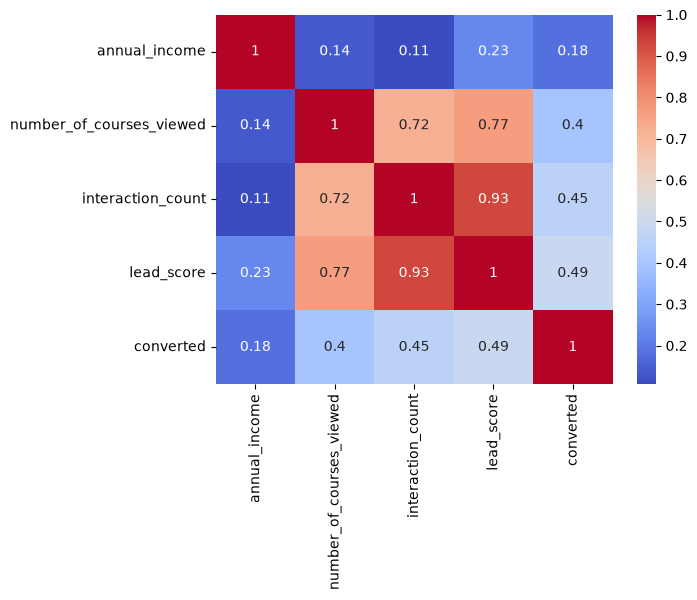

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = df.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')

In [35]:
corr_pair1 = ["interaction_count", "lead_score"]
corr_pair2 = ["number_of_courses_viewed", "lead_score"]
corr_pair3 = ["number_of_courses_viewed", "interaction_count"]
corr_pair4 = ["annual_income", "interaction_count"]

all_pairs = [corr_pair1, corr_pair2, corr_pair3, corr_pair4]

for pair in all_pairs:
    feature1, feature2 = pair
    r = computer_correlation(df_copy, feature1, feature2)
    print(f"Correlation between {feature1} and {feature2}: {r:.2f}")

Correlation between interaction_count and lead_score: 0.92
Correlation between number_of_courses_viewed and lead_score: 0.76
Correlation between number_of_courses_viewed and interaction_count: 0.72
Correlation between annual_income and interaction_count: 0.12


### Question 3 ###

In [36]:
from sklearn.model_selection import train_test_split
SEED = 42
df_full_train, df_test = train_test_split(df_copy, test_size=0.2, random_state=SEED)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=SEED)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']


len(df_train), len(df_val), len(df_test)


(3000, 1000, 1000)

In [37]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

### EDA ###

In [38]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train.converted.value_counts(normalize=True)

converted
1    0.57075
0    0.42925
Name: proportion, dtype: float64

In [39]:
df_full_train.converted.mean().item()

0.57075

In [41]:
numeric_features = ['annual_income', 'lead_score', 'interaction_count', 'number_of_courses_viewed']
features = df_full_train.columns
categorical_features = [f for f in features if f not in numeric_features]
categorical_features.remove('converted')
categorical_features

['lead_source', 'industry', 'employment_status', 'location']

In [42]:
df_full_train[categorical_features].nunique()

lead_source          6
industry             7
employment_status    5
location             6
dtype: int64

In [43]:
df_full_train.converted.value_counts(normalize=True)

converted
1    0.57075
0    0.42925
Name: proportion, dtype: float64

In [44]:
df_full_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,events,healthcare,employed,south_america,47301.0,5,7,0.69,0
1,organic_search,technology,unemployed,asia,0.0,1,5,0.57,0
2,events,finance,unemployed,asia,47970.0,0,0,0.17,0
3,organic_search,retail,self_employed,south_america,52847.0,3,3,0.45,0
4,paid_ads,finance,employed,africa,73460.0,1,4,0.42,1


In [51]:
def get_feature_impact(df, feature_name, target_name, list_values: list[str]):
    all_values = {}
    for value in list_values:
        if value not in df[feature_name].unique():
            continue  # Skip values not present in the feature
        impact = round(float(df[df[feature_name] == value][target_name].mean()), 2)
        all_values[value] = impact

    return all_values

In [52]:
feature_impact_mappings = {}
for feature_name in categorical_features:
    impact_values = get_feature_impact(df_full_train, feature_name, 'converted', df_full_train[feature_name].unique().tolist())
    feature_impact_mappings[feature_name] = impact_values

feature_impact_mappings
    

{'lead_source': {'events': 0.41,
  'organic_search': 0.68,
  'paid_ads': 0.43,
  'social_media': 0.55,
  'referral': 0.76,
  'NA': 0.61},
 'industry': {'healthcare': 0.56,
  'technology': 0.61,
  'finance': 0.61,
  'retail': 0.55,
  'NA': 0.59,
  'education': 0.5,
  'manufacturing': 0.55},
 'employment_status': {'employed': 0.66,
  'unemployed': 0.44,
  'self_employed': 0.55,
  'student': 0.42,
  'NA': 0.58},
 'location': {'south_america': 0.53,
  'asia': 0.59,
  'africa': 0.55,
  'europe': 0.58,
  'north_america': 0.58,
  'NA': 0.6}}

### Difference risk ratio for categorical features ###

In [53]:
### Diff >0 tells it converts more than average, Diff <0 tells it converts less than average, 
### Risk >1 tells it is more likely to convert, Risk <1 tells it less likely to convert
global_rate = df_full_train.converted.mean()
df_group = df_full_train.groupby('lead_source').converted.agg(['mean', 'count'])
df_group['diff'] = round(df_group['mean'] - global_rate, 2)
df_group['risk'] = round(df_group['mean'] / global_rate, 2)
df_group

,mean,count,diff,risk
lead_source,,,,
NA,0.610169,118,0.04,1.07
events,0.411290,496,-0.16,0.72
organic_search,0.677579,1008,0.11,1.19
paid_ads,0.427957,930,-0.14,0.75
referral,0.763844,614,0.19,1.34
social_media,0.547962,834,-0.02,0.96


### Conversion Ratio ###

In [58]:
from IPython.display import display
global_rate = df_full_train.converted.mean()

risk_ratios = {}
for feature in categorical_features:
    df_group_risk = df_full_train.groupby(feature).converted.agg(['mean', 'count'])
    df_group_risk['risk'] = round(df_group_risk['mean'] / global_rate, 2)
    df_group_risk['diff'] = round(df_group_risk['mean'] - global_rate, 2)
    risk_ratios[feature] = df_group_risk.sort_values('risk', ascending=False)

    print(f"{feature} (global rate = {global_rate:.2f})")
    display(risk_ratios[feature])

lead_source (global rate = 0.57)


,mean,count,risk,diff
lead_source,,,,
referral,0.763844,614,1.34,0.19
organic_search,0.677579,1008,1.19,0.11
NA,0.610169,118,1.07,0.04
social_media,0.547962,834,0.96,-0.02
paid_ads,0.427957,930,0.75,-0.14
events,0.411290,496,0.72,-0.16


industry (global rate = 0.57)


,mean,count,risk,diff
industry,,,,
finance,0.613402,582,1.07,0.04
technology,0.611111,918,1.07,0.04
NA,0.587629,194,1.03,0.02
healthcare,0.559398,665,0.98,-0.01
retail,0.553741,735,0.97,-0.02
manufacturing,0.548969,388,0.96,-0.02
education,0.500000,518,0.88,-0.07


employment_status (global rate = 0.57)


,mean,count,risk,diff
employment_status,,,,
employed,0.656459,2090,1.15,0.09
NA,0.580247,162,1.02,0.01
self_employed,0.548276,580,0.96,-0.02
unemployed,0.435572,551,0.76,-0.14
student,0.419773,617,0.74,-0.15


location (global rate = 0.57)


,mean,count,risk,diff
location,,,,
NA,0.603550,169,1.06,0.03
asia,0.585308,844,1.03,0.01
europe,0.584821,896,1.02,0.01
north_america,0.576923,1092,1.01,0.01
africa,0.546154,390,0.96,-0.02
south_america,0.525452,609,0.92,-0.05


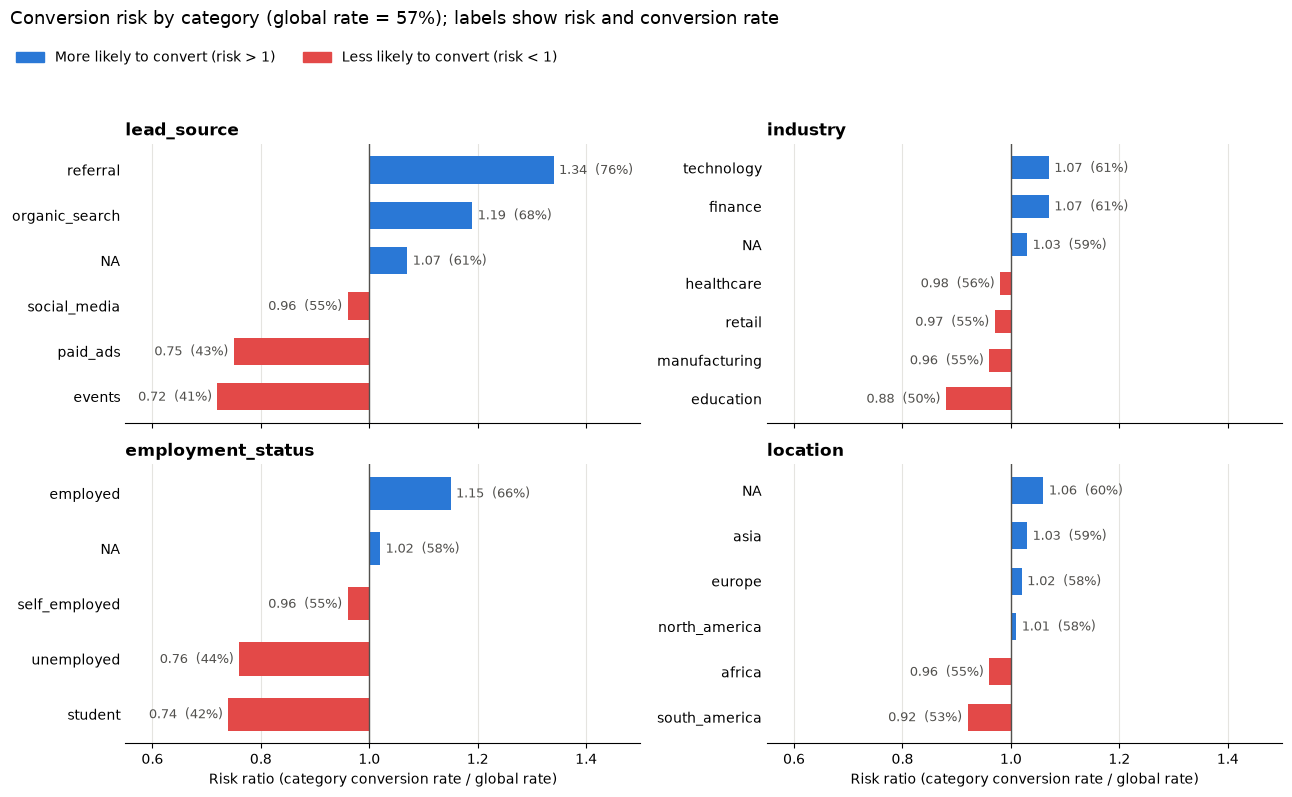

In [55]:
import matplotlib.pyplot as plt

MORE_LIKELY = '#2a78d6'   # blue: converts more than average (risk > 1)
LESS_LIKELY = '#e34948'   # red: converts less than average (risk < 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for ax, feature in zip(axes.flat, categorical_features):
    data = risk_ratios[feature].sort_values('risk')
    colors = [MORE_LIKELY if r > 1 else LESS_LIKELY for r in data['risk']]

    # bars start at 1.0 (= average), so they grow left for "less likely" and right for "more likely"
    ax.barh(data.index, data['risk'] - 1, left=1, color=colors, height=0.6)
    ax.axvline(1, color='#52514e', linewidth=1)

    for i, (risk, rate) in enumerate(zip(data['risk'], data['mean'])):
        offset = 0.01 if risk > 1 else -0.01
        ax.text(risk + offset, i, f'{risk:.2f}  ({rate:.0%})', va='center',
                ha='left' if risk > 1 else 'right', fontsize=9, color='#52514e')

    ax.set_title(feature, loc='left', fontsize=12, fontweight='bold')
    ax.set_xlim(0.55, 1.5)
    ax.grid(axis='x', color='#e5e4e0', linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.tick_params(axis='y', length=0)

for ax in axes[1]:
    ax.set_xlabel('Risk ratio (category conversion rate / global rate)')

fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=MORE_LIKELY),
                    plt.Rectangle((0, 0), 1, 1, color=LESS_LIKELY)],
           labels=['More likely to convert (risk > 1)', 'Less likely to convert (risk < 1)'],
           loc='upper left', bbox_to_anchor=(0.005, 0.955), ncol=2, frameon=False)
fig.suptitle(f'Conversion risk by category (global rate = {global_rate:.0%}); labels show risk and conversion rate',
             x=0.01, y=0.99, ha='left', fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.91))
plt.show()


In [66]:
from sklearn.metrics import mutual_info_score

def compute_mutual_info(df, feature1, feature2):
    x = df[feature1].values
    y = df[feature2].values

    mi = mutual_info_score(x, y)
    return round(mi, 2)

In [68]:
TARGET = 'converted'
for feature in categorical_features:
    mi = compute_mutual_info(df_full_train, feature, TARGET)
    print(f"Mutual information between {feature} and {TARGET}: {mi}")

print(compute_mutual_info(df_full_train, 'lead_source', 'employment_status'))

Mutual information between lead_source and converted: 0.03
Mutual information between industry and converted: 0.0
Mutual information between employment_status and converted: 0.02
Mutual information between location and converted: 0.0
0.0


In [79]:
df_full_train[numeric_features].corrwith(df_full_train[TARGET]).sort_values(ascending=False)

lead_score                  0.482078
interaction_count           0.450273
number_of_courses_viewed    0.393200
annual_income               0.188437
dtype: float64

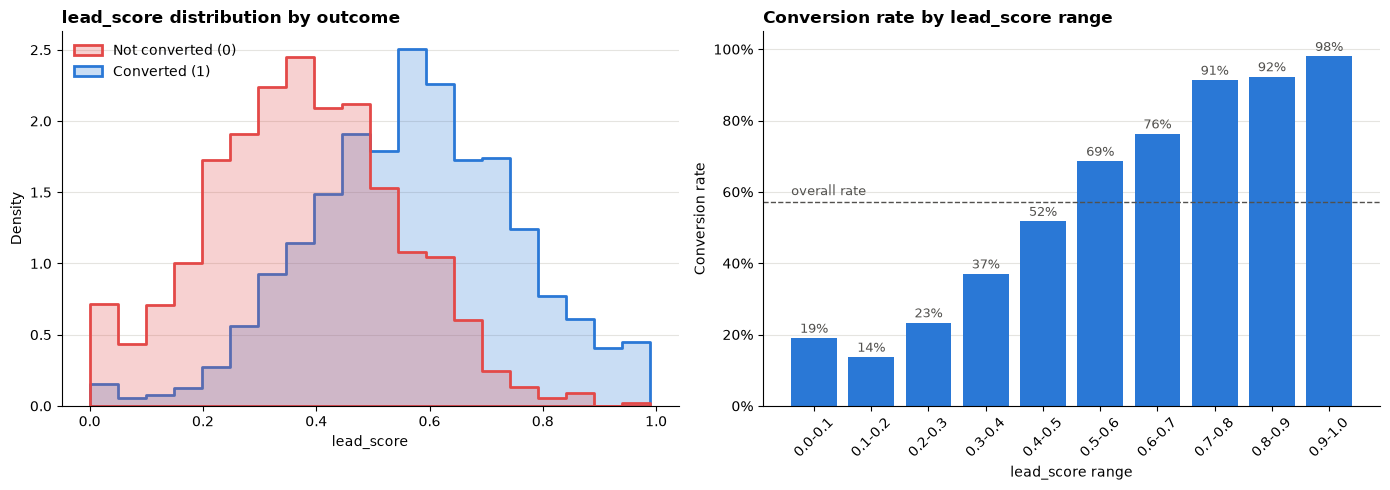

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

CONVERTED = '#2a78d6'       # blue
NOT_CONVERTED = '#e34948'   # red

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: distribution of lead_score for converted vs not converted
sns.histplot(data=df_full_train, x='lead_score', hue=TARGET, bins=20,
             element='step', stat='density', common_norm=False,
             palette={0: NOT_CONVERTED, 1: CONVERTED}, linewidth=2, ax=ax1)
ax1.legend(handles=ax1.get_legend().legend_handles, labels=['Not converted (0)', 'Converted (1)'],
           frameon=False, loc='upper left')
ax1.set_title('lead_score distribution by outcome', loc='left', fontweight='bold')
ax1.set_xlabel('lead_score')


# Right: conversion rate in each lead_score bin
bins = pd.cut(df_full_train['lead_score'], bins=10)
rate = df_full_train.groupby(bins, observed=True)[TARGET].agg(['mean', 'count'])
ax2.bar(range(len(rate)), rate['mean'], color=CONVERTED, width=0.8)
ax2.axhline(df_full_train[TARGET].mean(), color='#52514e', linewidth=1, linestyle='--')
ax2.text(-0.4, df_full_train[TARGET].mean() + 0.02, 'overall rate', ha='left', fontsize=9, color='#52514e')
for i, m in enumerate(rate['mean']):
    ax2.text(i, m + 0.015, f'{m:.0%}', ha='center', fontsize=9, color='#52514e')
ax2.set_xticks(range(len(rate)))
ax2.set_xticklabels([f'{max(b.left, 0):.1f}-{b.right:.1f}' for b in rate.index], rotation=45)
ax2.set_ylim(0, 1.05)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax2.set_title('Conversion rate by lead_score range', loc='left', fontweight='bold')
ax2.set_xlabel('lead_score range')
ax2.set_ylabel('Conversion rate')

for ax in (ax1, ax2):
    ax.grid(axis='y', color='#e5e4e0', linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()


### One Hot Encoding for Categorical Variable ###

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction import DictVectorizer


dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical_features + numeric_features].to_dict(orient='records')
train_dicts
X_train = dv.fit_transform(train_dicts)


val_dicts = df_val[categorical_features + numeric_features].to_dict(orient='records')
X_val = dv.transform(val_dicts)   # transform only, no fit

# dv.get_feature_names_out()

### Logistic Regression ###

In [ ]:
def sigmoid(z):
    z = np.clip(z, -500, 500)   # avoid overflow in np.exp for very large |z|
    return 1 / (1 + np.exp(-z))

def logistic_regression(X, y, num_steps, learning_rate, reg=0.0):
    n, d = X.shape
    # Initialize weights and bias (intercept)
    weights = np.zeros(d)
    bias = 0.0

    for _ in range(num_steps):
        # Linear combination of inputs and weights, plus bias
        z = np.dot(X, weights) + bias

        # Apply the sigmoid function to get probabilities
        predictions = sigmoid(z)

        # Calculate the error
        error = predictions - y

        # Average gradient over all rows (+ optional L2 regularization)
        grad_w = np.dot(X.T, error) / n + reg * weights
        grad_b = error.mean()

        # Update weights using gradient descent
        weights -= learning_rate * grad_w
        bias -= learning_rate * grad_b

    return weights, bias

def predict_proba(X, weights, bias):
    return sigmoid(np.dot(X, weights) + bias)

In [ ]:
# Scale features using train-set statistics, so annual_income (~80,000) doesn't dominate lead_score (0-1)
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_val_scaled = (X_val - mean) / std

weights, bias = logistic_regression(X_train_scaled, y_train, num_steps=1000, learning_rate=0.1)

y_val_pred = predict_proba(X_val_scaled, weights, bias)
accuracy = ((y_val_pred >= 0.5) == y_val).mean()
print(f"Validation accuracy: {accuracy:.3f}")

### Logistic Regression with scikit-learn ###

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=SEED)
model.fit(X_train, y_train)

y_val_proba = model.predict_proba(X_val)[:, 1]   # probability of converted = 1
y_val_pred = model.predict(X_val)                # 0 / 1 using a 0.5 threshold

print(f"Validation accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
print(f"Validation AUC:      {roc_auc_score(y_val, y_val_proba):.3f}")

In [ ]:
# Learned weight for each feature: > 0 pushes towards converting, < 0 pushes away
coefficients = pd.Series(model.coef_[0], index=dv.get_feature_names_out()).sort_values(ascending=False)
print(f"Intercept (bias): {model.intercept_[0]:.3f}")
coefficients.round(3)

In [ ]:
# Final model: train on train + validation, evaluate once on the untouched test set
y_full_train = df_full_train[TARGET].values

dv_full = DictVectorizer(sparse=False)
X_full_train = dv_full.fit_transform(df_full_train[categorical_features + numeric_features].to_dict(orient='records'))
X_test = dv_full.transform(df_test[categorical_features + numeric_features].to_dict(orient='records'))

final_model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=SEED)
final_model.fit(X_full_train, y_full_train)

y_test_proba = final_model.predict_proba(X_test)[:, 1]
y_test_pred = final_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_test_pred):.3f}")
print(f"Test AUC:      {roc_auc_score(y_test, y_test_proba):.3f}")

In [ ]:
# Predictions for a few test leads
df_test_results = df_test.copy()
df_test_results['converted_probability'] = y_test_proba.round(3)
df_test_results['converted_predicted'] = y_test_pred
df_test_results['converted_actual'] = y_test
df_test_results[['lead_source', 'employment_status', 'lead_score', 'interaction_count',
                 'converted_probability', 'converted_predicted', 'converted_actual']].head(10)